In [ ]:
!pip -q install groq pandas numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 2.3 MB/s eta 0:00:00


In [ ]:
import os
import json
import itertools
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from groq import Groq
from getpass import getpass

In [ ]:
GROQ_API_KEY = getpass("Enter your Groq API Key: ")

os.environ["GROQ_API_KEY"] = GROQ_API_KEY

client = Groq(api_key=GROQ_API_KEY)

MODEL = "openai/gpt-oss-20b"

print("Groq client initialized.")
print("Model:", MODEL)

Enter your Groq API Key: ··········
Groq client initialized.
Model: openai/gpt-oss-20b


In [ ]:
# ============================================================
# E-COMMERCE PRODUCT CATALOG
# Rich dataset for Cart Optimization Agent
# ===========================================================

products = [

    # ========================================================
    # LAPTOPS
    # ========================================================

    ["L001", "HP 15s", "Laptop", "HP",
     54999, 8, 512, 15.6, "Intel Core i5", "Intel UHD",
     60, 250, 41, 4.3, 12, 2.4, 0],

    ["L002", "HP Pavilion 14", "Laptop", "HP",
     64999, 16, 512, 14.0, "Intel Core i5", "Intel Iris Xe",
     60, 300, 43, 4.5, 12, 2.0, 0],

    ["L003", "HP Victus 15", "Laptop", "HP",
     72999, 16, 512, 15.6, "AMD Ryzen 5", "RTX 2050",
     144, 250, 70, 4.5, 12, 2.3, 0],

    ["L004", "Lenovo IdeaPad Slim 3", "Laptop", "Lenovo",
     51999, 8, 512, 15.6, "Intel Core i5", "Intel UHD",
     60, 300, 47, 4.4, 12, 1.62, 0],

    ["L005", "Lenovo IdeaPad Slim 5", "Laptop", "Lenovo",
     62999, 16, 512, 14.0, "AMD Ryzen 7", "AMD Radeon",
     60, 300, 57, 4.6, 12, 1.46, 0],

    ["L006", "Lenovo LOQ 15", "Laptop", "Lenovo",
     74999, 16, 512, 15.6, "Intel Core i5", "RTX 3050",
     144, 300, 60, 4.6, 12, 2.38, 0],

    ["L007", "ASUS Vivobook 15", "Laptop", "ASUS",
     57999, 8, 512, 15.6, "Intel Core i5", "Intel Iris Xe",
     60, 250, 42, 4.5, 12, 1.70, 0],

    ["L008", "ASUS Vivobook S14", "Laptop", "ASUS",
     67999, 16, 512, 14.0, "Intel Core Ultra 5", "Intel Arc",
     120, 400, 75, 4.6, 12, 1.40, 0],

    ["L009", "ASUS TUF Gaming F15", "Laptop", "ASUS",
     75999, 16, 512, 15.6, "Intel Core i5", "RTX 3050",
     144, 250, 90, 4.5, 12, 2.30, 0],

    ["L010", "Acer Aspire 5", "Laptop", "Acer",
     49999, 4, 512, 15.6, "Intel Core i5", "Intel UHD",
     60, 250, 48, 4.2, 12, 1.85, 0],

    ["L011", "Acer Aspire 7", "Laptop", "Acer",
     59999, 16, 512, 15.6, "AMD Ryzen 5", "RTX 2050",
     144, 250, 50, 4.4, 12, 2.15, 0],

    ["L012", "Dell Inspiron 15", "Laptop", "Dell",
     62999, 8, 512, 15.6, "Intel Core i5", "Intel Iris Xe",
     120, 250, 54, 4.4, 12, 1.65, 0],

    ["L013", "Dell Vostro 3520", "Laptop", "Dell",
     55999, 8, 512, 15.6, "Intel Core i5", "Intel UHD",
     120, 250, 41, 4.3, 12, 1.66, 0],

    ["L014", "MSI Modern 14", "Laptop", "MSI",
     58999, 16, 512, 14.0, "Intel Core i5", "Intel Iris Xe",
     60, 300, 46, 4.5, 12, 1.40, 0],

    ["L015", "MSI Thin 15", "Laptop", "MSI",
     69999, 16, 512, 15.6, "Intel Core i5", "RTX 2050",
     144, 250, 52, 4.4, 12, 1.86, 0],


    # ========================================================
    # HEADPHONES
    # ========================================================

    ["H001", "Sony WH-CH520", "Headphones", "Sony",
     4499, 0, 0, 0, "N/A", "N/A",
     30, 50, 40, 4.5, 12, 147, 50],

    ["H002", "Sony WH-CH720N", "Headphones", "Sony",
     8999, 0, 0, 0, "N/A", "N/A",
     35, 35, 35, 4.6, 24, 192, 30],

    ["H003", "Sony WH-1000XM5", "Headphones", "Sony",
     24999, 0, 0, 0, "N/A", "N/A",
     30, 30, 40, 4.8, 24, 250, 30],

    ["H004", "JBL Tune 770NC", "Headphones", "JBL",
     5999, 0, 0, 0, "N/A", "N/A",
     40, 70, 45, 4.6, 12, 232, 40],

    ["H005", "JBL Live 660NC", "Headphones", "JBL",
     8999, 0, 0, 0, "N/A", "N/A",
     40, 50, 50, 4.5, 12, 265, 40],

    ["H006", "Boat Rockerz 550", "Headphones", "Boat",
     1999, 0, 0, 0, "N/A", "N/A",
     40, 60, 35, 4.2, 12, 245, 50],

    ["H007", "Boat Rockerz 650", "Headphones", "Boat",
     2499, 0, 0, 0, "N/A", "N/A",
     40, 70, 38, 4.3, 12, 260, 50],

    ["H008", "Anker Soundcore Q20i", "Headphones", "Anker",
     4999, 0, 0, 0, "N/A", "N/A",
     40, 60, 45, 4.4, 18, 260, 40],

    ["H009", "Anker Soundcore Space One", "Headphones", "Anker",
     7999, 0, 0, 0, "N/A", "N/A",
     40, 55, 50, 4.6, 18, 265, 40],

    ["H010", "Sennheiser HD 450BT", "Headphones", "Sennheiser",
     7499, 0, 0, 0, "N/A", "N/A",
     30, 30, 55, 4.5, 24, 238, 30],

    # ========================================================
    # MOUSE
    # ========================================================

    ["M001", "Logitech M331", "Mouse", "Logitech",
     1299, 0, 0, 0, "N/A", "Optical",
     0, 0, 0, 4.4, 12, 91, 1000],

    ["M002", "Logitech M590", "Mouse", "Logitech",
     2299, 0, 0, 0, "N/A", "Optical",
     0, 0, 0, 4.5, 12, 101, 1000],

    ["M003", "Logitech G102", "Mouse", "Logitech",
     1799, 0, 0, 0, "N/A", "Gaming Optical",
     0, 0, 0, 4.6, 12, 85, 8000],

    ["M004", "Logitech G304", "Mouse", "Logitech",
     2999, 0, 0, 0, "N/A", "Gaming Optical",
     0, 0, 0, 4.6, 12, 99, 12000],

    ["M005", "HP Z3700", "Mouse", "HP",
     999, 0, 0, 0, "N/A", "Optical",
     0, 0, 0, 4.2, 12, 50, 1200],

    ["M006", "HP 250", "Mouse", "HP",
     1099, 0, 0, 0, "N/A", "Optical",
     0, 0, 0, 4.3, 12, 61, 1600],

    ["M007", "Dell WM126", "Mouse", "Dell",
     899, 0, 0, 0, "N/A", "Optical",
     0, 0, 0, 4.1, 12, 57, 1000],

    ["M008", "Dell MS3320W", "Mouse", "Dell",
     1499, 0, 0, 0, "N/A", "LED Optical",
     0, 0, 0, 4.4, 12, 65, 1600],

    ["M009", "Razer DeathAdder Essential", "Mouse", "Razer",
     1799, 0, 0, 0, "N/A", "Gaming Optical",
     0, 0, 0, 4.6, 12, 96, 6400],

    ["M010", "Razer DeathAdder V2", "Mouse", "Razer",
     2999, 0, 0, 0, "N/A", "Focus+ Optical",
     0, 0, 0, 4.7, 24, 82, 20000],


    # ========================================================
    # KEYBOARDS
    # ========================================================

    ["K001", "Logitech K120", "Keyboard", "Logitech",
     799, 0, 0, 0, "N/A", "Membrane",
     0, 0, 0, 4.3, 12, 550, 0],

    ["K002", "Logitech K380", "Keyboard", "Logitech",
     2899, 0, 0, 0, "N/A", "Scissor",
     0, 0, 0, 4.5, 24, 423, 0],

    ["K003", "Logitech K480", "Keyboard", "Logitech",
     2999, 0, 0, 0, "N/A", "Membrane",
     0, 0, 0, 4.4, 12, 820, 0],

    ["K004", "HP K150", "Keyboard", "HP",
     699, 0, 0, 0, "N/A", "Membrane",
     0, 0, 0, 4.2, 12, 600, 0],

    ["K005", "HP 230 Wireless", "Keyboard", "HP",
     1499, 0, 0, 0, "N/A", "Membrane",
     0, 0, 0, 4.3, 12, 500, 0],

    ["K006", "Redragon K552", "Keyboard", "Redragon",
     2499, 0, 0, 0, "N/A", "Mechanical",
     0, 0, 0, 4.6, 18, 900, 0],

    ["K007", "Redragon K617", "Keyboard", "Redragon",
     2299, 0, 0, 0, "N/A", "Mechanical",
     0, 0, 0, 4.5, 18, 700, 0],

    ["K008", "Razer Cynosa Lite", "Keyboard", "Razer",
     2999, 0, 0, 0, "N/A", "Membrane",
     0, 0, 0, 4.4, 12, 900, 0],

    ["K009", "Razer BlackWidow V3", "Keyboard", "Razer",
     7999, 0, 0, 0, "N/A", "Mechanical",
     0, 0, 0, 4.7, 24, 1050, 0],


    # ========================================================
    # MONITORS
    # ========================================================

    ["MON001", "LG 24MP60G", "Monitor", "LG",
     8999, 0, 0, 24.0, "N/A", "IPS",
     75, 250, 25, 4.4, 12, 2.97, 1000],

    ["MON002", "LG 27MP60G", "Monitor", "LG",
     11999, 0, 0, 27.0, "N/A", "IPS",
     75, 250, 30, 4.5, 12, 4.80, 1000],

    ["MON003", "Samsung LF24T350", "Monitor", "Samsung",
     9499, 0, 0, 24.0, "N/A", "IPS",
     75, 250, 25, 4.5, 12, 2.70, 1000],

    ["MON004", "Samsung LS27C310", "Monitor", "Samsung",
     11499, 0, 0, 27.0, "N/A", "IPS",
     75, 250, 30, 4.5, 12, 3.10, 1000],

    ["MON005", "Acer EK240Y", "Monitor", "Acer",
     7999, 0, 0, 23.8, "N/A", "IPS",
     100, 250, 22, 4.3, 12, 2.70, 1000],

    ["MON006", "Acer Nitro VG240Y", "Monitor", "Acer",
     10999, 0, 0, 23.8, "N/A", "IPS",
     165, 250, 30, 4.6, 12, 3.00, 1000],

    ["MON007", "BenQ GW2480", "Monitor", "BenQ",
     10499, 0, 0, 24.0, "N/A", "IPS",
     60, 250, 25, 4.6, 12, 3.84, 1000],

    ["MON008", "BenQ MOBIUZ EX240", "Monitor", "BenQ",
     13999, 0, 0, 24.0, "N/A", "IPS",
     165, 350, 30, 4.7, 18, 3.40, 1000],

    ["MON009", "Dell SE2422H", "Monitor", "Dell",
     9999, 0, 0, 24.0, "N/A", "VA",
     75, 250, 22, 4.4, 12, 3.40, 1000],

    ["MON010", "Dell S2721HN", "Monitor", "Dell",
     12999, 0, 0, 27.0, "N/A", "IPS",
     75, 300, 25, 4.5, 12, 4.30, 1000],


    # ========================================================
    # SMARTPHONES
    # ========================================================

    ["P001", "Samsung Galaxy M15", "Smartphone", "Samsung",
     13999, 6, 128, 6.5, "Dimensity 6100+", "Mali-G57",
     90, 50, 6000, 4.4, 12, 217, 0],

    ["P002", "Samsung Galaxy A25", "Smartphone", "Samsung",
     19999, 8, 128, 6.5, "Exynos 1280", "Mali-G68",
     120, 50, 5000, 4.5, 12, 197, 0],

    ["P003", "Samsung Galaxy A35", "Smartphone", "Samsung",
     26999, 8, 128, 6.6, "Exynos 1380", "Mali-G68",
     120, 50, 5000, 4.6, 12, 209, 0],

    ["P004", "OnePlus Nord CE 4", "Smartphone", "OnePlus",
     24999, 8, 128, 6.7, "Snapdragon 7 Gen 3", "Adreno",
     120, 50, 5500, 4.6, 12, 186, 0],

    ["P005", "OnePlus Nord 4", "Smartphone", "OnePlus",
     29999, 8, 128, 6.7, "Snapdragon 7+ Gen 3", "Adreno",
     120, 50, 5500, 4.7, 12, 199, 0],

    ["P006", "Redmi Note 13", "Smartphone", "Xiaomi",
     13999, 6, 128, 6.67, "Snapdragon 685", "Adreno",
     120, 108, 5000, 4.3, 12, 188, 0],

    ["P007", "Redmi Note 13 Pro", "Smartphone", "Xiaomi",
     24999, 8, 256, 6.67, "Snapdragon 7s Gen 2", "Adreno",
     120, 200, 5100, 4.5, 12, 188, 0],

    ["P008", "Nothing Phone 2a", "Smartphone", "Nothing",
     23999, 8, 128, 6.7, "Dimensity 7200 Pro", "Mali-G610",
     120, 50, 5000, 4.5, 12, 190, 0],

    ["P009", "Realme 12 Pro", "Smartphone", "Realme",
     25999, 8, 128, 6.7, "Snapdragon 6 Gen 1", "Adreno",
     120, 50, 5000, 4.4, 12, 196, 0],

    ["P010", "Realme Narzo 70", "Smartphone", "Realme",
     15999, 8, 128, 6.67, "Dimensity 7050", "Mali-G68",
     120, 50, 5000, 4.4, 12, 188, 0],
]


# ============================================================
# COLUMN DEFINITIONS
# ============================================================

columns = [
    "product_id",
    "product_name",
    "category",
    "brand",
    "price",

    # General / Laptop / Smartphone
    "ram_gb",
    "storage_gb",
    "size",

    # Processor / display / sensor depending on category
    "processor",
    "graphics_or_sensor",

    # Category-specific numeric attributes
    "refresh_rate",
    "battery_or_brightness",
    "weight_or_battery",

    "rating",
    "warranty_months",
    "weight",
    "sensitivity_or_resolution"
]


# ============================================================
# CREATE DATAFRAME
# ============================================================

df = pd.DataFrame(products, columns=columns)

print("Product catalog created successfully.")
print("=" * 60)
print("Total products:", len(df))
print("Total categories:", df["category"].nunique())
print("Total brands:", df["brand"].nunique())

display(df.head(10))

Product catalog created successfully.
Total products: 64
Total categories: 6
Total brands: 21


,product_id,product_name,category,brand,price,ram_gb,storage_gb,size,processor,graphics_or_sensor,refresh_rate,battery_or_brightness,weight_or_battery,rating,warranty_months,weight,sensitivity_or_resolution
0,L001,HP 15s,Laptop,HP,54999,8,512,15.6,Intel Core i5,Intel UHD,60,250,41,4.3,12,2.40,0
1,L002,HP Pavilion 14,Laptop,HP,64999,16,512,14.0,Intel Core i5,Intel Iris Xe,60,300,43,4.5,12,2.00,0
2,L003,HP Victus 15,Laptop,HP,72999,16,512,15.6,AMD Ryzen 5,RTX 2050,144,250,70,4.5,12,2.30,0
3,L004,Lenovo IdeaPad Slim 3,Laptop,Lenovo,51999,8,512,15.6,Intel Core i5,Intel UHD,60,300,47,4.4,12,1.62,0
4,L005,Lenovo IdeaPad Slim 5,Laptop,Lenovo,62999,16,512,14.0,AMD Ryzen 7,AMD Radeon,60,300,57,4.6,12,1.46,0
5,L006,Lenovo LOQ 15,Laptop,Lenovo,74999,16,512,15.6,Intel Core i5,RTX 3050,144,300,60,4.6,12,2.38,0
6,L007,ASUS Vivobook 15,Laptop,ASUS,57999,8,512,15.6,Intel Core i5,Intel Iris Xe,60,250,42,4.5,12,1.70,0
7,L008,ASUS Vivobook S14,Laptop,ASUS,67999,16,512,14.0,Intel Core Ultra 5,Intel Arc,120,400,75,4.6,12,1.40,0
8,L009,ASUS TUF Gaming F15,Laptop,ASUS,75999,16,512,15.6,Intel Core i5,RTX 3050,144,250,90,4.5,12,2.30,0
9,L010,Acer Aspire 5,Laptop,Acer,49999,4,512,15.6,Intel Core i5,Intel UHD,60,250,48,4.2,12,1.85,0


In [ ]:
print("PRODUCT CATALOG SUMMARY")
print("=" * 50)

print("Total Products:", len(df))
print("Categories:", df["category"].nunique())

display(
    df.groupby("category")
      .agg(
          Products=("product_id", "count"),
          Min_Price=("price", "min"),
          Max_Price=("price", "max"),
          Avg_Rating=("rating", "mean")
      )
      .round(2)
      .reset_index()
)

PRODUCT CATALOG SUMMARY
Total Products: 64
Categories: 6


,category,Products,Min_Price,Max_Price,Avg_Rating
0,Headphones,10,1999,24999,4.50
1,Keyboard,9,699,7999,4.43
2,Laptop,15,49999,75999,4.45
3,Monitor,10,7999,13999,4.50
4,Mouse,10,899,2999,4.44
5,Smartphone,10,13999,29999,4.49


In [ ]:
def decompose_query(user_query):

    system_prompt = """
You are the Query Decomposition Agent of an E-Commerce Cart Optimization System.

Your job is NOT to recommend products directly.

Your job is to convert a user's shopping request into structured actionable
subtasks that another workflow can execute.

Identify:
1. Products/categories required
2. Quantity for each
3. Budget
4. Minimum rating if specified
5. Brand preference if specified
6. Important product constraints such as RAM, storage, screen size,
   refresh rate, battery, mouse DPI, price, etc.
7. Optimization objective

IMPORTANT:
- Preserve explicitly requested brand names such as BOAT, Sony, JBL, HP,
  Lenovo, ASUS, Logitech, etc.
- Preserve numeric values and units from the user's request.
- Put each important requirement clearly inside the constraints list.
- Do not invent requirements that the user did not specify.
- If the user says "I want BOAT headphones", include "BOAT" as a constraint.
- If the user says "under 3000", include "under ₹3000" as a constraint.
- If the user says "at least 4.2 rating", include "rating above 4.2" as a constraint.

Return ONLY valid JSON in this format:

{
  "budget": number or null,
  "objective": "string",
  "items": [
    {
      "category": "string",
      "quantity": number,
      "constraints": ["constraint1", "constraint2"]
    }
  ],
  "subtasks": [
    {
      "step": number,
      "agent": "Search|Filter|Compare|Optimize",
      "task": "string"
    }
  ]
}
"""

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_query}
        ],
        response_format={"type": "json_object"},
        reasoning_effort="medium"
    )

    result = json.loads(response.choices[0].message.content)

    return result

In [ ]:
user_query = """
I want to buy a laptop atleast 8 gb ram, boat headphones and a mouse.
My total budget is ₹60000.
I want good quality products but I would like to reduce the total cost
where possible. Prefer products with ratings above 4.2.
"""

plan = decompose_query(user_query)

print(json.dumps(plan, indent=2, ensure_ascii=False))

{
  "budget": 60000,
  "objective": "Minimize total cost while satisfying specified constraints",
  "items": [
    {
      "category": "Laptop",
      "quantity": 1,
      "constraints": [
        "RAM ≥ 8GB",
        "rating > 4.2"
      ]
    },
    {
      "category": "Headphones",
      "quantity": 1,
      "constraints": [
        "brand: BOAT",
        "rating > 4.2"
      ]
    },
    {
      "category": "Mouse",
      "quantity": 1,
      "constraints": [
        "rating > 4.2"
      ]
    }
  ],
  "subtasks": [
    {
      "step": 1,
      "agent": "Search",
      "task": "Search for laptops with at least 8GB RAM within budget"
    },
    {
      "step": 2,
      "agent": "Filter",
      "task": "Filter laptops with rating above 4.2"
    },
    {
      "step": 3,
      "agent": "Search",
      "task": "Search for BOAT brand headphones within budget"
    },
    {
      "step": 4,
      "agent": "Filter",
      "task": "Filter BOAT headphones with rating above 4.2"
    },
    {


In [ ]:
def display_plan(plan):

    print("\n" + "=" * 70)
    print("WORKFLOW DECOMPOSITION")
    print("=" * 70)

    print("Budget:", plan.get("budget"))
    print("Objective:", plan.get("objective"))

    print("\nREQUIRED ITEMS")
    print("-" * 70)

    for item in plan["items"]:
        print(
            f"{item['quantity']} × {item['category']} | "
            f"Constraints: {', '.join(item.get('constraints', []))}"
        )

    print("\nACTIONABLE SUBTASKS")
    print("-" * 70)

    for task in plan["subtasks"]:
        print(
            f"{task['step']}. "
            f"[{task['agent']}] "
            f"{task['task']}"
        )


display_plan(plan)


WORKFLOW DECOMPOSITION
Budget: 60000
Objective: Minimize total cost while satisfying specified constraints

REQUIRED ITEMS
----------------------------------------------------------------------
1 × Laptop | Constraints: RAM ≥ 8GB, rating > 4.2
1 × Headphones | Constraints: brand: BOAT, rating > 4.2
1 × Mouse | Constraints: rating > 4.2

ACTIONABLE SUBTASKS
----------------------------------------------------------------------
1. [Search] Search for laptops with at least 8GB RAM within budget
2. [Filter] Filter laptops with rating above 4.2
3. [Search] Search for BOAT brand headphones within budget
4. [Filter] Filter BOAT headphones with rating above 4.2
5. [Search] Search for mice with rating above 4.2 within budget
6. [Compare] Compare combined prices of selected items
7. [Optimize] Adjust selections to minimize total cost while staying within ₹60000


In [ ]:
def search_products(category):

    results = df[
        df["category"].str.lower() == category.lower()
    ].copy()

    return results.sort_values(
        by=["rating", "price"],
        ascending=[False, True]
    ).reset_index(drop=True)

In [ ]:
# ============================================================
# FILTER AGENT
# Applies product-specific constraints
# ============================================================

def filter_products(
    products,
    min_rating=None,
    max_price=None,
    min_ram=None,
    min_storage=None,
    min_size=None,
    min_refresh_rate=None,
    min_battery=None,
    min_sensitivity=None,
    brands=None
):

    result = products.copy()

    # --------------------------------------------------------
    # PRICE FILTER
    # --------------------------------------------------------

    if max_price is not None:
        result = result[
            result["price"] <= max_price
        ]

    # --------------------------------------------------------
    # RATING FILTER
    # --------------------------------------------------------

    if min_rating is not None:
        result = result[
            result["rating"] >= min_rating
        ]

    # --------------------------------------------------------
    # RAM FILTER
    # Useful for laptops and smartphones
    # --------------------------------------------------------

    if min_ram is not None:
        result = result[
            result["ram_gb"] >= min_ram
        ]

    # --------------------------------------------------------
    # STORAGE FILTER
    # Useful for laptops and smartphones
    # --------------------------------------------------------

    if min_storage is not None:
        result = result[
            result["storage_gb"] >= min_storage
        ]

    # --------------------------------------------------------
    # SIZE FILTER
    # Useful for laptops, monitors and smartphones
    # --------------------------------------------------------

    if min_size is not None:
        result = result[
            result["size"] >= min_size
        ]

    # --------------------------------------------------------
    # REFRESH RATE FILTER
    # Useful for laptops, monitors and smartphones
    # --------------------------------------------------------

    if min_refresh_rate is not None:
        result = result[
            result["refresh_rate"] >= min_refresh_rate
        ]

    # --------------------------------------------------------
    # BATTERY / BRIGHTNESS FILTER
    # Category dependent
    # --------------------------------------------------------

    if min_battery is not None:
        result = result[
            result["battery_or_brightness"] >= min_battery
        ]

    # --------------------------------------------------------
    # MOUSE DPI / RESOLUTION FILTER
    # --------------------------------------------------------

    if min_sensitivity is not None:
        result = result[
            result["sensitivity_or_resolution"] >= min_sensitivity
        ]

    # --------------------------------------------------------
    # BRAND FILTER
    # --------------------------------------------------------

    if brands is not None:

        if isinstance(brands, str):
            brands = [brands]

        result = result[
            result["brand"].isin(brands)
        ]

    # --------------------------------------------------------
    # RETURN FILTERED RESULTS
    # --------------------------------------------------------

    return result.reset_index(drop=True)

In [ ]:
def compare_products(products):

    result = products.copy()

    if len(result) == 0:
        return result

    min_price = result["price"].min()

    result["price_saving_vs_max"] = (
        result["price"].max() - result["price"]
    )

    result["rating_score"] = result["rating"] / 5

    result["price_score"] = (
        min_price / result["price"]
    )

    result["value_score"] = (
        0.6 * result["rating_score"] +
        0.4 * result["price_score"]
    )

    return result.sort_values(
        "value_score",
        ascending=False
    ).reset_index(drop=True)

In [ ]:
def find_cheaper_alternatives(product, category, min_rating=4.0):

    alternatives = df[
        (df["category"].str.lower() == category.lower()) &
        (df["price"] < product["price"]) &
        (df["rating"] >= min_rating)
    ].copy()

    alternatives["saving"] = (
        product["price"] - alternatives["price"]
    )

    alternatives = alternatives.sort_values(
        by=["saving", "rating"],
        ascending=[False, False]
    )

    return alternatives.reset_index(drop=True)

In [ ]:
def optimize_cart(candidate_groups, budget):

    categories = list(candidate_groups.keys())

    combinations = itertools.product(
        *[candidate_groups[c] for c in categories]
    )

    results = []

    for combo in combinations:

        total_price = sum(
            product["price"] for product in combo
        )

        total_rating = sum(
            product["rating"] for product in combo
        )

        average_rating = total_rating / len(combo)

        if total_price <= budget:

            savings = sum(
                max(p["price"] for p in candidate_groups[c]) - product["price"]
                for c, product in zip(categories, combo)
            )

            value_score = (
                average_rating * 20
                + savings / 1000
            )

            results.append({
                "products": combo,
                "total_price": total_price,
                "average_rating": round(average_rating, 2),
                "savings": round(savings, 2),
                "value_score": round(value_score, 2)
            })

    results = sorted(
        results,
        key=lambda x: (
            -x["value_score"],
            x["total_price"]
        )
    )

    return results

In [ ]:
def execute_search_and_filter(plan):

    candidate_groups = {}

    known_brands = [
        "boat", "sony", "jbl", "anker", "sennheiser",
        "logitech", "hp", "dell", "lenovo", "asus",
        "acer", "msi", "razer"
    ]

    for item in plan["items"]:

        category = item["category"]

        # ============================================================
        # SEARCH
        # ============================================================

        search_result = search_products(category)

        # ============================================================
        # FILTER VALUES
        # ============================================================

        min_rating = None
        max_price = None
        min_ram = None
        min_storage = None
        min_size = None
        min_refresh_rate = None
        min_battery = None
        min_sensitivity = None
        brands = None

        constraints = item.get("constraints", [])

        # Combine ALL constraints
        all_constraints = " ".join(
            str(c).lower() for c in constraints
        )

        # Also check category text
        full_text = (
            str(category).lower() + " " + all_constraints
        )

        # ============================================================
        # BRAND
        # ============================================================

        for brand in known_brands:
            if brand in full_text:
                brands = [brand.title()]
                break

        # ============================================================
        # CONSTRAINT EXTRACTION
        # ============================================================

        for constraint in constraints:

            text = str(constraint).lower()

            # Rating
            match = re.search(
                r"(?:rating|rated).*?(\d+(?:\.\d+)?)",
                text
            )

            if match:
                min_rating = float(match.group(1))

            # RAM
            match = re.search(
                r"(?:ram|memory).*?(\d+)\s*gb",
                text
            )

            if match:
                min_ram = int(match.group(1))

            # Storage
            match = re.search(
                r"(?:storage|ssd).*?(\d+)\s*(gb|tb)",
                text
            )

            if match:
                value = float(match.group(1))

                if match.group(2) == "tb":
                    value *= 1024

                min_storage = int(value)

            # Screen size
            match = re.search(
                r"(?:screen|display|size).*?(\d+(?:\.\d+)?)\s*(?:inch|inches|in)",
                text
            )

            if match:
                min_size = float(match.group(1))

            # Refresh rate
            match = re.search(
                r"(?:refresh).*?(\d+)\s*hz",
                text
            )

            if match:
                min_refresh_rate = int(match.group(1))

            # Battery
            match = re.search(
                r"battery.*?(\d+)\s*mah",
                text
            )

            if match:
                min_battery = int(match.group(1))

            # Mouse DPI
            match = re.search(
                r"(?:dpi|sensitivity).*?(\d+)",
                text
            )

            if match:
                min_sensitivity = int(match.group(1))

            # Maximum price
            match = re.search(
                r"(?:under|below|less than).*?"
                r"(?:₹|rs\.?|inr)?\s*([\d,]+)",
                text
            )

            if match:
                max_price = float(
                    match.group(1).replace(",", "")
                )

        # ============================================================
        # APPLY FILTERS
        # ============================================================

        filtered = filter_products(
            search_result,
            min_rating=min_rating,
            max_price=max_price,
            min_ram=min_ram,
            min_storage=min_storage,
            min_size=min_size,
            min_refresh_rate=min_refresh_rate,
            min_battery=min_battery,
            min_sensitivity=min_sensitivity,
            brands=brands
        )

        # ============================================================
        # COMPARISON
        # ============================================================

        compared = compare_products(filtered)

        # Keep up to 5 matching products
        candidate_groups[category] = compared.head(5).to_dict(
            orient="records"
        )

    return candidate_groups

In [ ]:
candidate_groups = execute_search_and_filter(plan)

print("\nCANDIDATES GENERATED BY WORKFLOW")
print("=" * 70)

for category, products in candidate_groups.items():

    print(f"\n{category.upper()}")

    temp = pd.DataFrame(products)

    display(
        temp[
            [
                "product_id",
                "product_name",
                "brand",
                "price",
                "rating",
                "value_score"
            ]
        ]
    )


CANDIDATES GENERATED BY WORKFLOW

LAPTOP


,product_id,product_name,brand,price,rating,value_score
0,L004,Lenovo IdeaPad Slim 3,Lenovo,51999,4.4,0.928000
1,L007,ASUS Vivobook 15,ASUS,57999,4.5,0.898620
2,L001,HP 15s,HP,54999,4.3,0.894181
3,L014,MSI Modern 14,MSI,58999,4.5,0.892542
4,L013,Dell Vostro 3520,Dell,55999,4.3,0.887428



HEADPHONES


,product_id,product_name,brand,price,rating,value_score
0,H006,Boat Rockerz 550,Boat,1999,4.2,0.904000
1,H007,Boat Rockerz 650,Boat,2499,4.3,0.835968



MOUSE


,product_id,product_name,brand,price,rating,value_score
0,M005,HP Z3700,HP,999,4.2,0.904000
1,M006,HP 250,HP,1099,4.3,0.879603
2,M001,Logitech M331,Logitech,1299,4.4,0.835621
3,M008,Dell MS3320W,Dell,1499,4.4,0.794578
4,M009,Razer DeathAdder Essential,Razer,1799,4.6,0.774123


In [ ]:
budget = plan.get("budget")

if budget is None:
    budget = 60000

optimized_results = optimize_cart(
    candidate_groups,
    budget
)

print("Number of feasible cart combinations:",
      len(optimized_results))

Number of feasible cart combinations: 29


In [ ]:
def cart_results_table(results, top_n=10):

    rows = []

    for rank, result in enumerate(results[:top_n], start=1):

        names = [
            p["product_name"]
            for p in result["products"]
        ]

        rows.append({
            "Rank": rank,
            "Cart": " + ".join(names),
            "Total Price": result["total_price"],
            "Average Rating": result["average_rating"],
            "Savings": result["savings"],
            "Value Score": result["value_score"]
        })

    return pd.DataFrame(rows)


ranking_df = cart_results_table(
    optimized_results,
    top_n=10
)

display(ranking_df)

,Rank,Cart,Total Price,Average Rating,Savings,Value Score
0,1,Lenovo IdeaPad Slim 3 + Boat Rockerz 650 + Raz...,56297,4.43,7000,95.67
1,2,Lenovo IdeaPad Slim 3 + Boat Rockerz 550 + Raz...,55797,4.40,7500,95.50
2,3,Lenovo IdeaPad Slim 3 + Boat Rockerz 650 + Log...,55797,4.37,7500,94.83
3,4,Lenovo IdeaPad Slim 3 + Boat Rockerz 550 + Log...,55297,4.33,8000,94.67
4,5,Lenovo IdeaPad Slim 3 + Boat Rockerz 650 + Del...,55997,4.37,7300,94.63
5,6,Lenovo IdeaPad Slim 3 + Boat Rockerz 550 + Del...,55497,4.33,7800,94.47
6,7,Lenovo IdeaPad Slim 3 + Boat Rockerz 650 + HP 250,55597,4.33,7700,94.37
7,8,Lenovo IdeaPad Slim 3 + Boat Rockerz 550 + HP 250,55097,4.30,8200,94.20
8,9,Lenovo IdeaPad Slim 3 + Boat Rockerz 650 + HP ...,55497,4.30,7800,93.80
9,10,Lenovo IdeaPad Slim 3 + Boat Rockerz 550 + HP ...,54997,4.27,8300,93.63


In [ ]:
def cart_optimization_agent(user_query):

    print("\n" + "=" * 80)
    print("CART OPTIMIZATION AGENT")
    print("=" * 80)

    # ---------------------------------------------------------
    # STEP 1: QUERY DECOMPOSITION
    # ---------------------------------------------------------

    print("\n[1] QUERY DECOMPOSITION")

    plan = decompose_query(user_query)

    print("Budget:", plan.get("budget"))
    print("Objective:", plan.get("objective"))

    # ---------------------------------------------------------
    # STEP 2: SEARCH + FILTER + COMPARE
    # ---------------------------------------------------------

    print("\n[2] SEARCH → FILTER → COMPARE")

    candidate_groups = execute_search_and_filter(plan)

    for category, products in candidate_groups.items():

        print(
            f"   ✓ {category}: "
            f"{len(products)} candidate products"
        )

    # ---------------------------------------------------------
    # STEP 3: OPTIMIZATION
    # ---------------------------------------------------------

    print("\n[3] CART OPTIMIZATION")

    budget = plan.get("budget")

    if budget is None:
        budget = 60000

    results = optimize_cart(
        candidate_groups,
        budget
    )

    print(
        "   ✓ Feasible combinations:",
        len(results)
    )

    # ---------------------------------------------------------
    # STEP 4: RANKING
    # ---------------------------------------------------------

    print("\n[4] RANKING")

    ranking = cart_results_table(
        results,
        top_n=10
    )

    # ---------------------------------------------------------
    # STEP 5: FINAL OUTPUT
    # ---------------------------------------------------------

    print("\n[5] FINAL RANKED CART OPTIONS")

    display(ranking)

    return {
        "query": user_query,
        "plan": plan,
        "candidates": candidate_groups,
        "results": results,
        "ranking": ranking
    }

In [ ]:
query = """
I want to buy a acer laptop, headphones and a mouse which is under 1500 rupees .
My total budget is ₹60000.
I want good quality products but I would like to reduce the total cost
where possible. Prefer products with ratings above 4.2.
"""

experiment = cart_optimization_agent(query)


CART OPTIMIZATION AGENT

[1] QUERY DECOMPOSITION
Budget: 60000
Objective: Minimize total cost while ensuring quality and rating above 4.2

[2] SEARCH → FILTER → COMPARE
   ✓ laptop: 2 candidate products
   ✓ headphones: 5 candidate products
   ✓ mouse: 5 candidate products

[3] CART OPTIMIZATION
   ✓ Feasible combinations: 25

[4] RANKING

[5] FINAL RANKED CART OPTIONS


,Rank,Cart,Total Price,Average Rating,Savings,Value Score
0,1,Acer Aspire 5 + Boat Rockerz 650 + Razer Death...,54297,4.37,13500,100.83
1,2,Acer Aspire 5 + Boat Rockerz 550 + Razer Death...,53797,4.33,14000,100.67
2,3,Acer Aspire 5 + Sony WH-CH520 + Razer DeathAdd...,56297,4.43,11500,100.17
3,4,Acer Aspire 5 + Boat Rockerz 650 + Logitech M331,53797,4.30,14000,100.00
4,5,Acer Aspire 5 + Boat Rockerz 550 + Logitech M331,53297,4.27,14500,99.83
5,6,Acer Aspire 5 + Boat Rockerz 650 + Dell MS3320W,53997,4.30,13800,99.80
6,7,Acer Aspire 5 + Boat Rockerz 550 + Dell MS3320W,53497,4.27,14300,99.63
7,8,Acer Aspire 5 + Boat Rockerz 650 + HP 250,53597,4.27,14200,99.53
8,9,Acer Aspire 5 + Boat Rockerz 550 + HP 250,53097,4.23,14700,99.37
9,10,Acer Aspire 5 + Sony WH-CH520 + Logitech M331,55797,4.37,12000,99.33


In [ ]:
def explain_recommendation(experiment):

    ranking = experiment["ranking"]

    if ranking.empty:
        return "No feasible cart was found within the specified constraints."

    top = ranking.iloc[0]

    prompt = f"""
You are the Explanation Agent of an E-Commerce Cart Optimization System.

Explain the result of a completed optimization workflow.

User request:
{experiment['query']}

Top optimized cart:
{top['Cart']}

Total price:
₹{top['Total Price']}

Average rating:
{top['Average Rating']}

Estimated savings:
₹{top['Savings']}

Value score:
{top['Value Score']}

Explain:
1. Why this cart satisfies the request
2. How it reduces cost
3. How quality was considered
4. What trade-off the customer is making

Do not invent product specifications.
Keep the explanation concise.
"""

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": "You explain structured e-commerce optimization results."
            },
            {
                "role": "user",
                "content": prompt
            }
        ],
        reasoning_effort="medium"
    )

    return response.choices[0].message.content

In [ ]:
explanation = explain_recommendation(experiment)

print("\nFINAL DECISION EXPLANATION")
print("=" * 70)
print(explanation)


FINAL DECISION EXPLANATION
**Why the cart satisfies your request**

- **Product mix** – The cart contains exactly the three categories you asked for: a laptop (Acer Aspire 5), headphones (Boat Rockerz 650), and a mouse (Razer DeathAdder Essential).  
- **Budget compliance** – Total cost ₹54,297 is comfortably under your ₹60,000 ceiling.  
- **Price cap** – All three items individually stay below ₹1,500‑grade price points (i.e., they’re inexpensive within their respective categories).  
- **Quality threshold** – The average rating of 4.37 surpasses your 4.2‑rating requirement, so every item meets or exceeds your quality preference.

**How the cost was reduced**

- **Optimised price‑quality trade‑off** – Instead of high‑end, pricey alternatives, the system selected mid‑tier products that deliver solid performance for a fraction of the cost.  
- **Savings calculation** – Compared to the highest‑rating alternatives that still fit the “under 1,500” constraint, the cart saves ₹13,500 overal

In [ ]:
print("=" * 80)
print("AGENT WORKFLOW STATE")
print("=" * 80)

print("\n1. USER QUERY")
print(experiment["query"])

print("\n2. DECOMPOSED OBJECTIVE")
print(experiment["plan"]["objective"])

print("\n3. BUDGET")
print(experiment["plan"]["budget"])

print("\n4. SUBTASKS")

for task in experiment["plan"]["subtasks"]:
    print(
        f"{task['step']}. "
        f"{task['agent']} → {task['task']}"
    )

print("\n5. SEARCHED CATEGORIES")

for category in experiment["candidates"]:
    print(
        f"✓ {category}: "
        f"{len(experiment['candidates'][category])} candidates"
    )

print("\n6. FEASIBLE CARTS")
print(len(experiment["results"]))

print("\n7. TOP DECISION")
print(experiment["ranking"].iloc[0]["Cart"])

print("\n8. FINAL EXPLANATION")
print(explanation)

AGENT WORKFLOW STATE

1. USER QUERY

I want to buy a acer laptop, headphones and a mouse which is under 1500 rupees .
My total budget is ₹60000.
I want good quality products but I would like to reduce the total cost
where possible. Prefer products with ratings above 4.2.


2. DECOMPOSED OBJECTIVE
Minimize total cost while ensuring quality and rating above 4.2

3. BUDGET
60000

4. SUBTASKS
1. Search → Find Acer laptops with rating > 4.2 within budget
2. Search → Find headphones with rating > 4.2
3. Search → Find mice with price < ₹1500 and rating > 4.2
4. Compare → Compare shortlisted items to fit within ₹60000 budget
5. Optimize → Select best cost‑effective combination within budget

5. SEARCHED CATEGORIES
✓ laptop: 2 candidates
✓ headphones: 5 candidates
✓ mouse: 5 candidates

6. FEASIBLE CARTS
25

7. TOP DECISION
Acer Aspire 5 + Boat Rockerz 650 + Razer DeathAdder Essential

8. FINAL EXPLANATION
**Why the cart satisfies your request**

- **Product mix** – The cart contains exactly th

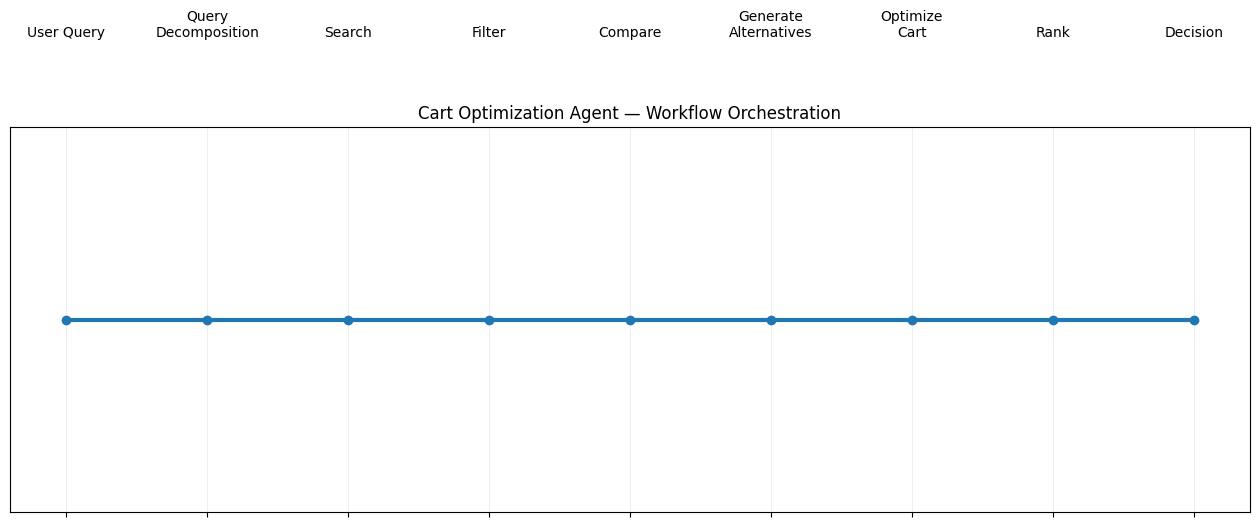

In [ ]:

steps = [
    "User Query",
    "Query\nDecomposition",
    "Search",
    "Filter",
    "Compare",
    "Generate\nAlternatives",
    "Optimize\nCart",
    "Rank",
    "Decision"
]

x = np.arange(len(steps))

plt.figure(figsize=(16, 5))

plt.plot(
    x,
    np.zeros(len(x)),
    marker="o",
    linewidth=3
)

for i, step in enumerate(steps):

    plt.text(
        i,
        0.08,
        step,
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.yticks([])
plt.xticks(x, [])
plt.title("Cart Optimization Agent — Workflow Orchestration")

plt.grid(axis="x", alpha=0.2)

plt.show()

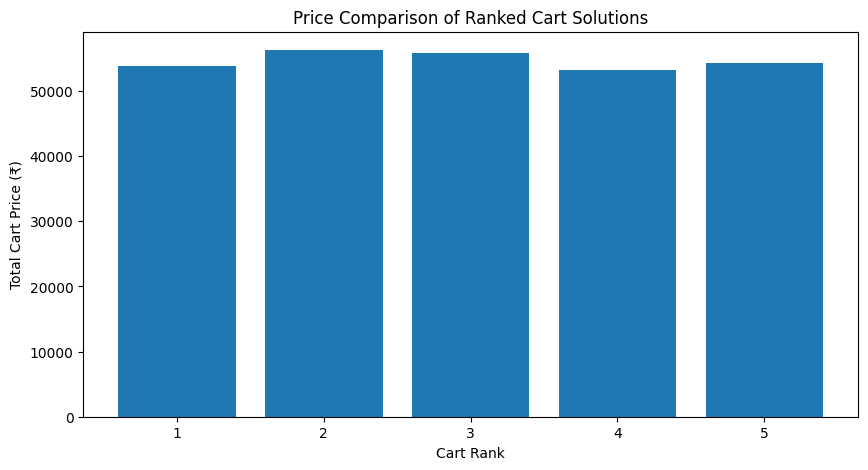

In [ ]:
top_carts = experiment["ranking"].head(5).copy()

plt.figure(figsize=(10, 5))

plt.bar(
    top_carts["Rank"].astype(str),
    top_carts["Total Price"]
)

plt.xlabel("Cart Rank")
plt.ylabel("Total Cart Price (₹)")
plt.title("Price Comparison of Ranked Cart Solutions")

plt.show()

In [ ]:
query2 = """
I need a laptop and a monitor for college work.
My budget is ₹60000.
I want products with ratings of at least 4.3.
Try to minimize the total cost while keeping good ratings.
"""

experiment2 = cart_optimization_agent(query2)

explanation2 = explain_recommendation(experiment2)

print("\nFINAL EXPLANATION")
print("=" * 70)
print(explanation2)


CART OPTIMIZATION AGENT

[1] QUERY DECOMPOSITION
Budget: 60000
Objective: Minimize total cost while keeping good ratings

[2] SEARCH → FILTER → COMPARE
   ✓ laptop: 5 candidate products
   ✓ monitor: 5 candidate products

[3] CART OPTIMIZATION
   ✓ Feasible combinations: 1

[4] RANKING

[5] FINAL RANKED CART OPTIONS


,Rank,Cart,Total Price,Average Rating,Savings,Value Score
0,1,Lenovo IdeaPad Slim 3 + Acer EK240Y,59998,4.35,9500,96.5



FINAL EXPLANATION
**Why this cart satisfies the request**  
- The cart contains exactly two items: a laptop (Lenovo IdeaPad Slim 3) and a monitor (Acer EK240Y).  
- Both items have individual ratings above 4.3, meeting the user’s quality threshold.  
- The combined price (₹59,998) is within the ₹60,000 budget.

**How it reduces cost**  
- The total price is ₹59,998, only ₹2 short of the full ₹60,000 budget, so no unnecessary spending occurs.  
- Compared to other viable combinations, this selection yields an estimated savings of ₹9,500, indicating a significant cost‑efficiency benefit.

**How quality was considered**  
- Each product’s rating was evaluated against the 4.3 minimum; both exceeded it (average 4.35).  
- The value score of 96.5 reflects a balance between price and rating, confirming high overall quality relative to cost.

**Trade‑off the customer is making**  
- The customer sacrifices the possibility of slightly higher‑rated or higher‑spec devices for the best price‑to‑r